# Exploratory Data Analysis (EDA)
В данном ноутбуке для Итогового проекта по дисциплине «Автоматизация процессов разработки и тестирования моделей машинного обучения» мы проводим первичный анализ датасета UCI Credit Card.

In [5]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.append(os.getcwd())

from src import config

if not config.DATA_RAW.exists():
    print('Data not found. Downloading...')
    os.system('python -m src.data.download')
else:
    print('Data already exists.')

df = pd.read_csv(config.DATA_RAW)
df = df.rename(columns={'default.payment.next.month': 'default_payment_next_month'})
df.head()

Data already exists.


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


### 1. Распределение целевой переменной (Target)
Проверяем дисбаланс классов.

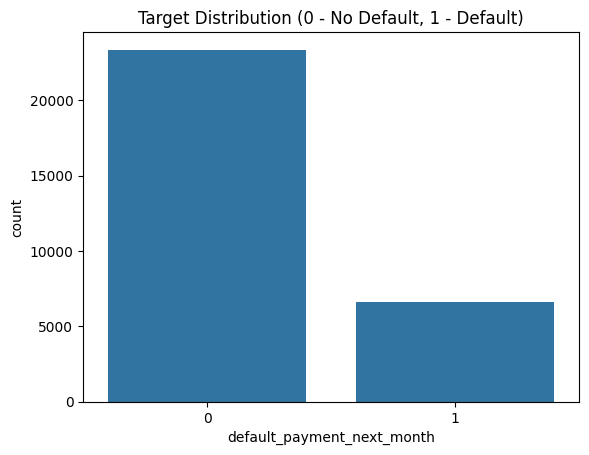

Доля дефолтов: 0.2212


In [6]:
sns.countplot(data=df, x='default_payment_next_month')
plt.title('Target Distribution (0 - No Default, 1 - Default)')
plt.show()

print('Доля дефолтов:', round(df['default_payment_next_month'].mean(), 4))

### 2. Влияние кредитного лимита на дефолт
Смотрим, есть ли разница в `LIMIT_BAL` между теми, кто вернул кредит, и теми, кто ушёл в дефолт.

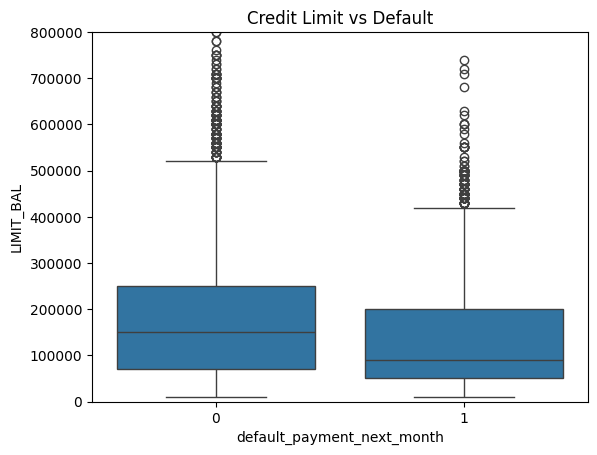

In [7]:
sns.boxplot(data=df, x='default_payment_next_month', y='LIMIT_BAL')
plt.title('Credit Limit vs Default')
plt.ylim(0, 800000)
plt.show()

### 3. Корреляционная матрица (Топ-признаки)
Выделяем признаки, которые сильнее всего коррелируют с целевой переменной.

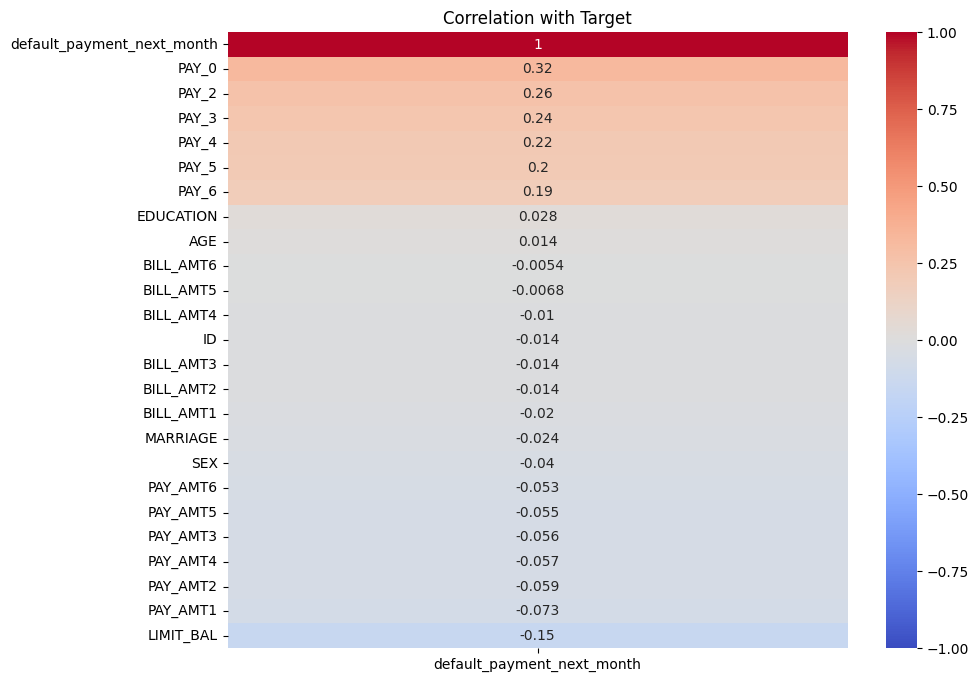

In [8]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr[['default_payment_next_month']].sort_values(
    by='default_payment_next_month', ascending=False), 
    annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation with Target')
plt.show()